# Digital Image Processing - Lab Task 02
## Environment Setup & Step 2: Image Loading and Properties
This section initializes our virtual environment libraries, loads the input image, and inspects its core dimensions and data type.

In [42]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Step 2: Load the Image and Print Properties
image_path = 'image.jpg'
image = cv.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Image not found at {image_path}")

print("--- Step 2: Image Properties ---")
print("Image Shape:", image.shape)
print("Image Data Type:", image.dtype)

--- Step 2: Image Properties ---
Image Shape: (678, 452, 3)
Image Data Type: uint8


## Step 3: Image Inspection
In this step, we inspect pixel dimensions, index specific pixel values (top-left and center), and calculate the global/per-channel minimum and maximum values.

In [43]:
# Step 3: Inspect the Image
height, width, channels = image.shape
print("\n--- Step 3: Image Inspection ---")
print(f"Height: {height}, Width: {width}, Channels: {channels}")

# Top-left and center pixels using [row, column] indexing
top_left_pixel = image[0, 0]
center_row = height // 2
center_col = width // 2
center_pixel = image[center_row, center_col]

print(f"Top-Left Pixel [0, 0] (BGR): {top_left_pixel}")
print(f"Center Pixel [{center_row}, {center_col}] (BGR): {center_pixel}")

# Global and per-channel min/max values
print(f"Global Minimum: {np.min(image)}, Global Maximum: {np.max(image)}")
print(f"Blue Channel - Min: {np.min(image[:, :, 0])}, Max: {np.max(image[:, :, 0])}")
print(f"Green Channel - Min: {np.min(image[:, :, 1])}, Max: {np.max(image[:, :, 1])}")
print(f"Red Channel - Min: {np.min(image[:, :, 2])}, Max: {np.max(image[:, :, 2])}")




--- Step 3: Image Inspection ---
Height: 678, Width: 452, Channels: 3
Top-Left Pixel [0, 0] (BGR): [11 79 92]
Center Pixel [339, 226] (BGR): [46 57 61]
Global Minimum: 0, Global Maximum: 255
Blue Channel - Min: 0, Max: 255
Green Channel - Min: 0, Max: 255
Red Channel - Min: 0, Max: 255


## Step 4: Color Conversion and Channel Analysis
**Explanation:** OpenCV loads images in **BGR** format by default, whereas Matplotlib expects **RGB**. If displayed directly without conversion, the colors appear inverted (e.g., reds look bluish). Here we separate channels, convert to RGB/Grayscale, compute the center pixel HEX value, and plot a 2x3 grid.


--- Step 4: Center Pixel HEX Value ---
Center Pixel RGB: (np.uint8(61), np.uint8(57), np.uint8(46))
Center Pixel HEX: #3d392e


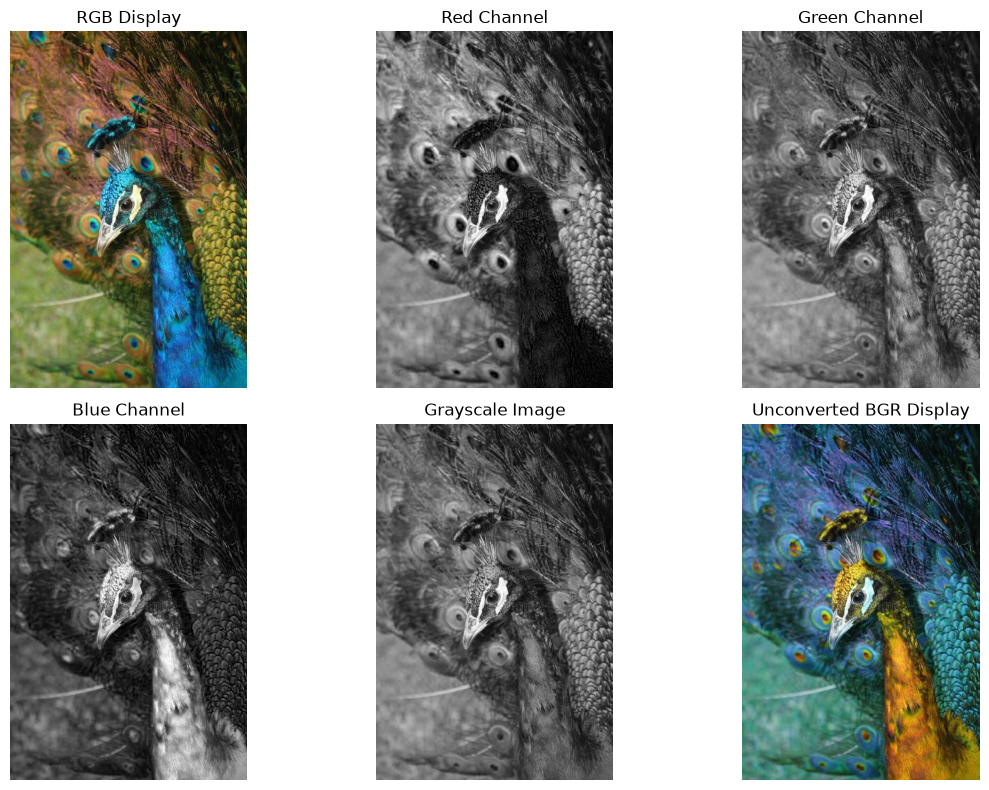

In [44]:
# Step 4: Convert Colors, Separate Channels, and HEX Conversion
# Convert BGR to RGB
image_rgb = cv.cvtColor(image, cv.COLOR_BGR2RGB)

# Convert to Grayscale
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

# Separate individual channels from the BGR image
b, g, r = cv.split(image)

# Convert center pixel from BGR to RGB, then to HEX
center_bgr = image[center_row, center_col]
# BGR to RGB for center pixel: element-wise reverse
center_rgb_val = (center_bgr[2], center_bgr[1], center_bgr[0])
center_hex = "#{:02x}{:02x}{:02x}".format(center_rgb_val[0], center_rgb_val[1], center_rgb_val[2])
print(f"\n--- Step 4: Center Pixel HEX Value ---")
print(f"Center Pixel RGB: {center_rgb_val}")
print(f"Center Pixel HEX: {center_hex}")

# Create a 2 x 3 figure
plt.figure(figsize=(12, 8))

# 1. RGB Display
plt.subplot(2, 3, 1)
plt.imshow(image_rgb)
plt.title("RGB Display")
plt.axis('off')

# 2. Red Channel
plt.subplot(2, 3, 2)
plt.imshow(r, cmap='gray')
plt.title("Red Channel")
plt.axis('off')

# 3. Green Channel
plt.subplot(2, 3, 3)
plt.imshow(g, cmap='gray')
plt.title("Green Channel")
plt.axis('off')

# 4. Blue Channel
plt.subplot(2, 3, 4)
plt.imshow(b, cmap='gray')
plt.title("Blue Channel")
plt.axis('off')

# 5. Grayscale Image
plt.subplot(2, 3, 5)
plt.imshow(gray_image, cmap='gray')
plt.title("Grayscale Image")
plt.axis('off')

# 6. Unconverted BGR Display (using matplotlib directly without conversion)
plt.subplot(2, 3, 6)
plt.imshow(image)
plt.title("Unconverted BGR Display")
plt.axis('off')

plt.tight_layout()
plt.show()

## Step 5: Crop, Resize, and Save
Here we slice a 100x100 region of interest from the center of the image, resize it to 200x200 using `cv.resize()`, display them side by side, and save the output as `resized_crop.png`.


--- Step 5: Crop and Resize ---
Crop Shape: (100, 100, 3)
Resized Crop Shape: (200, 200, 3)


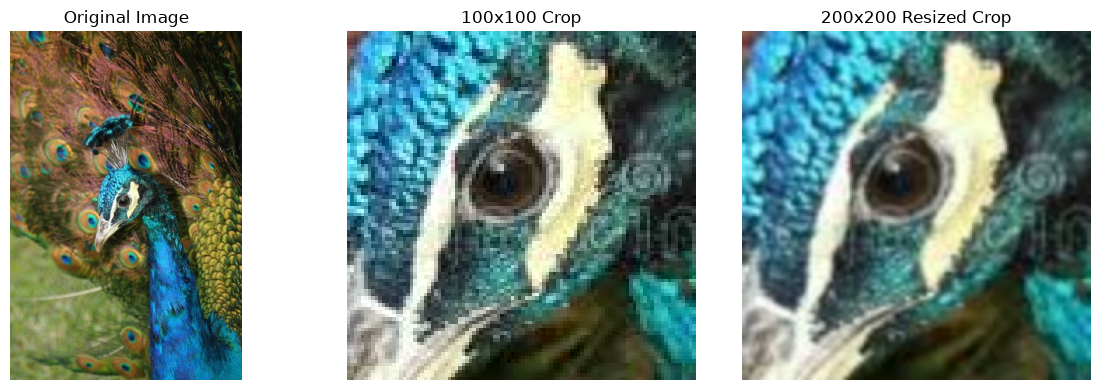

resized_crop.png saved successfully: True


In [45]:
# ==========================================
# Step 5: Crop, Resize, Display, and Save
# ==========================================

# Crop an exact 100 x 100 region using the center of the image
y_start = center_row - 50
y_end = center_row + 50
x_start = center_col - 50
x_end = center_col + 50

cropped_image = image[y_start:y_end, x_start:x_end]
print(f"\n--- Step 5: Crop and Resize ---")
print("Crop Shape:", cropped_image.shape)

# Resize the cropped image and convert to RGB for the display and saving workflow
resized_rgb = cv.resize(
    cv.cvtColor(cropped_image, cv.COLOR_BGR2RGB), (200, 200)
)
print("Resized Crop Shape:", resized_rgb.shape)

# Display original image, crop, and resized image side by side using Matplotlib
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(cropped_image, cv.COLOR_BGR2RGB))
plt.title("100x100 Crop")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(resized_rgb)  # Display resized_rgb directly (no extra cvtColor)
plt.title("200x200 Resized Crop")
plt.axis("off")

plt.tight_layout()
plt.show()

# Convert the resized RGB image back to BGR and save it as resized_crop.png
resized_bgr = cv.cvtColor(resized_rgb, cv.COLOR_RGB2BGR)
success = cv.imwrite("resized_crop.png", resized_bgr)
print("resized_crop.png saved successfully:", success)

## Step 6: Grayscale Histogram Analysis
**Explanation:** The histogram shows the frequency of pixel intensity values (0-255). It indicates overall image brightness and contrast distribution, but it *does not* show the spatial location (where pixels are located) within the image.

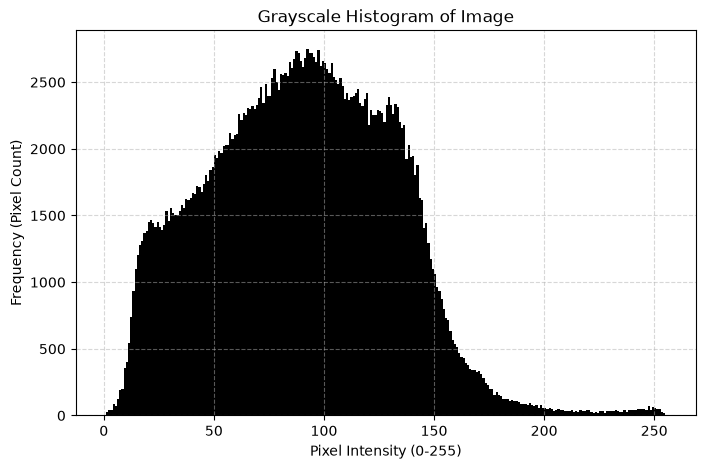


--- Step 6: Histogram Completed ---
Histogram saved as 'grayscale_histogram.png'


In [46]:
# Step 6: Create a Histogram
# Flatten the grayscale image and plot a 256-bin histogram
plt.figure(figsize=(8, 5))
plt.hist(gray_image.ravel(), bins=256, range=[0, 256], color='black')
plt.title("Grayscale Histogram of Image")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Frequency (Pixel Count)")
plt.grid(True, linestyle='--', alpha=0.5)

# Save the plot as grayscale_histogram.png
plt.savefig('grayscale_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n--- Step 6: Histogram Completed ---")
print("Histogram saved as 'grayscale_histogram.png'")

## Step 7: Demonstrate Bit Depth and Quantization
**Explanation:** Spatial resolution refers to the pixel dimensions (grid size) of an image, while bit depth refers to the number of intensity levels available per pixel (e.g., 8-bit has 256 levels down to 1-bit with 2 levels). Quantization reduces the bit depth, resulting in fewer unique intensity values.


--- Step 7: Bit Depth Unique Values ---
8-bit unique values: 256
4-bit unique values: 16
2-bit unique values: 4
1-bit unique values: 2


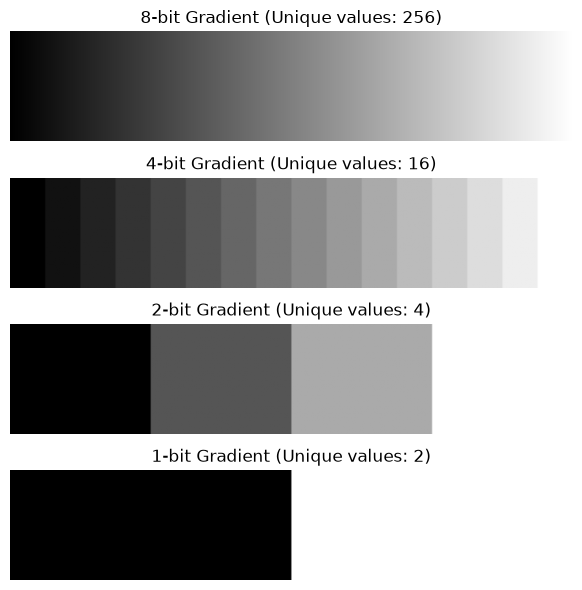

In [47]:
import matplotlib.pyplot as plt
import numpy as np

# Create an 8-bit horizontal grayscale gradient from 0 to 255 (width=256, height=50)
gradient_8bit = np.tile(np.linspace(0, 255, 256, dtype=np.uint8), (50, 1))


# Corrected quantization function
def quantize_image(img, bits):
  levels = 2**bits
  step = 256 // levels
  # Scale down to discrete levels, then stretch back to span the full 0-255 range
  quantized = (img // step) * (255 // (levels - 1))
  return quantized.astype(np.uint8)


gradient_4bit = quantize_image(gradient_8bit, 4)
gradient_2bit = quantize_image(gradient_8bit, 2)
gradient_1bit = quantize_image(gradient_8bit, 1)

# Print unique value counts
print("\n--- Step 7: Bit Depth Unique Values ---")
print("8-bit unique values:", len(np.unique(gradient_8bit)))
print("4-bit unique values:", len(np.unique(gradient_4bit)))
print("2-bit unique values:", len(np.unique(gradient_2bit)))
print("1-bit unique values:", len(np.unique(gradient_1bit)))

# Display original and quantized gradients in one figure
plt.figure(figsize=(10, 6))

plt.subplot(4, 1, 1)
plt.imshow(gradient_8bit, cmap='gray', vmin=0, vmax=255)
plt.title(f"8-bit Gradient (Unique values: {len(np.unique(gradient_8bit))})")
plt.axis('off')

plt.subplot(4, 1, 2)
plt.imshow(gradient_4bit, cmap='gray', vmin=0, vmax=255)
plt.title(f"4-bit Gradient (Unique values: {len(np.unique(gradient_4bit))})")
plt.axis('off')

plt.subplot(4, 1, 3)
plt.imshow(gradient_2bit, cmap='gray', vmin=0, vmax=255)
plt.title(f"2-bit Gradient (Unique values: {len(np.unique(gradient_2bit))})")
plt.axis('off')

plt.subplot(4, 1, 4)
plt.imshow(gradient_1bit, cmap='gray', vmin=0, vmax=255)
plt.title(f"1-bit Gradient (Unique values: {len(np.unique(gradient_1bit))})")
plt.axis('off')

plt.tight_layout()
plt.show()